# Ariketa 4.1 — Erregresio lineal sinplea 📉 (EGITEKO)

UD3n **kategoriak** iragarri genituen. Orain **zenbaki jarraitu bat** iragarriko dugu.

Problema:

```text
autoaren pisua (lb)
        ↓
erregai-eraginkortasuna (mpg)
```

Eredua:

$$
\hat{y} = w x + b
$$

Eta lotura garrantzitsua:

> **Erregresio lineala neurona baten zatirik sinpleena bezala ikus daiteke: weighted sum + bias, aktibazio ez-linealik gabe.**

### Nola lan egin

- 🟢 **KOMENTATU:** azaldu zure hitzekin.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU ZEROTIK:** kode-zati labur bat idatzi.


# 1.1 — Sailkapenetik erregresiora 🟢

| | UD3: Sailkapena | UD4: Erregresioa |
|---|---|---|
| Irteera | kategoria | zenbaki jarraitua |
| Adibidea | spam / ez-spam | 23.5 mpg |
| API | `fit()` / `predict()` | `fit()` / `predict()` |
| Eredu sinplea | Logistic Regression | Linear Regression |

Gaur **aldagai bakarra** erabiliko dugu:

```text
x = weight
y = mpg
```

⚠️ `mpg` = **miles per gallon**. Balio handiagoa = erregai-eraginkortasun handiagoa.

Beraz:

```text
pisu handiagoa → normalean mpg txikiagoa
```

Horrek esan nahi du auto astunagoak, oro har, **erregai gehiago** behar duela distantzia bera egiteko.


# 1.2 — Dataset-a prestatu 🔎

Lehenengo, behar ditugun bi zutabeak bakarrik aukeratuko ditugu:

```text
weight
mpg
```

Ondoren bakarrik egiaztatuko ditugu balio faltak.

> **Ez dugu beste zutabe batean dagoen NaN batengatik auto bat alferrik ezabatu nahi.**


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


# ============================================================
# DATASET-A
# ============================================================

df_raw = sns.load_dataset("mpg")

# 🟡 HUTSUNEAK:
# ariketa honetan behar ditugun bi zutabeak bakarrik
df = df_raw[[
    "weight",
    "mpg"
]].copy()


print(
    "Shape:",
    df.shape
)

print(
    "\nNull-ak:"
)

print(
    df.isnull().sum()
)


# Beharrezkoa balitz bakarrik kendu.
df = df.dropna()


print(
    "\nPisu tartea:",
    round(df["weight"].min()),
    "-",
    round(df["weight"].max()),
    "lb"
)

print(
    "mpg tartea:",
    round(df["mpg"].min(), 1),
    "-",
    round(df["mpg"].max(), 1)
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Zergatik aukeratzen ditugu weight eta mpg LEHENENGO,
# eta gero egiten dugu dropna()?
#
# ERANTZUNA:
# Hasieran `df_raw.dropna()` egingo bagenu, erabiliko ez ditugun beste zutabe batzuetan
# (adibidez `horsepower`) balio nuluak dituzten errenkadak ezabatuko lirateke, alferrik
# datu erabilgarriak galduz. Lehenik behar ditugun zutabeak bakarrik aukeratuz (`weight` eta `mpg`),
# bi zutabe horietan nuluak diren errenkadak bakarrik ezabatzen ditugu `dropna()` bidez.
#

Shape: (398, 2)

Null-ak:
weight    0
mpg       0
dtype: int64

Pisu tartea: 1613 - 5140 lb
mpg tartea: 9.0 - 46.6


# 1.3 — X / y eta TRAIN / TEST ✂️

Oraingo workflow ezaguna:

```text
X = feature-a
y = target-a
        ↓
TRAIN / TEST
```

Ez dugu scaling egingo.

Zergatik?

> **Malda (`w`) jatorrizko unitateetan interpretatu nahi dugu: mpg / lb.**

Gainera, `LinearRegression`-en iragarpenak ez du scaling-a behar bezala funtzionatzeko.


In [2]:
X = df[[
    "weight"
]]

y = df[
    "mpg"
]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,

    # 🟡 HUTSUNEA: %20 TEST
    test_size=0.2,

    random_state=42
)


print(
    "TRAIN:",
    X_train.shape[0]
)

print(
    "TEST:",
    X_test.shape[0]
)


# ============================================================
# 🟢 KOMENTATU
# ============================================================
#
# Zergatik EZ dugu stratify=y erabiltzen hemen?
#
# ERANTZUNA:
# `stratify=y` sailkapen-arazoetan (klase kategorialak ditugunean) bakarrik erabiltzen da,
# train eta test banaketetan klaseen proportzio bera mantentzeko. Kasu honetan erregresio-arazo
# bat dugu eta helburu-aldagaia (`y` / `mpg`) aldagai jarraitua (zenbakizkoa) da. Aldagai
# jarraitu batekin `stratify=y` erabiliko bagenu, scikit-learn-ek errorea (ValueError) emango
# luke, ez dagoelako balio diskreturik edo klase definiturik estratifikatu ahal izateko.

TRAIN: 318
TEST: 80


# 1.4 — Erregresio-zuzena ikasi 📏

`LinearRegression()`-ek honelako eredua bilatuko du:

$$
\hat{y} = w x + b
$$

non:

```text
w → malda / coefficient
b → ebakidura / intercept
```

### Ohar garrantzitsua DL-rako

Gaur scikit-learn erabiltzen ari gara.

`LinearRegression()`-ek **Ordinary Least Squares** soluzioa kalkulatzen du; ez du guk gero eskuz egingo dugun gradient-descent iterazio-loop sinplea erabiltzen.

Geroagoko ariketa batean:

```text
predict
→ error / MSE
→ gradient
→ w eta b eguneratu
→ repeat
```

eskuz eraikiko dugu, Deep Learning-erako zubia egiteko.


In [3]:
# ============================================================
# 🟡 HUTSUNEAK BETE
# ============================================================

modeloa = LinearRegression()

modeloa.fit(
    X_train,
    y_train
)


w = modeloa.coef_[0]

b = modeloa.intercept_


print(
    "Malda w:",
    round(w, 5),
    "mpg/lb"
)

print(
    "Ebakidura b:",
    round(b, 2),
    "mpg"
)

print(
    "\nIkasitako ekuazioa:"
)

print(
    f"ŷ = {w:.5f} · weight + {b:.2f}"
)

Malda w: -0.00781 mpg/lb
Ebakidura b: 46.78 mpg

Ikasitako ekuazioa:
ŷ = -0.00781 · weight + 46.78


# 1.5 — 🟢 Interpretatu `w` eta `b`

### A) Malda

`w` negatiboa bada:

> autoaren pisua handitzean, aurreikusitako mpg-a **txikiagoa** da (gutxitu egiten da).

Kodearekin kalkulatuko dugu **100 lb gehiago** izatearen efektua.

### B) Ebakidura

`b` matematikoki:

> `weight = 0` izango balitz aurreikusitako mpg-a da.

Baina gure autoek ez dute 0 lb pisatzen.

> Beraz, `b` beharrezkoa da zuzenaren ekuazioan, baina ez dugu zertan interpretazio fisiko errealista eman.

### 🟢 Galdera

Zergatik da arriskutsua `b` esatea “0 lb-ko auto baten benetako eraginkortasuna” dela?

**ERANTZUNA:**
0 lb-ko autorik ez dagoelako: `weight = 0` TRAIN datuen tartetik (~1600–5100 lb) oso urrun dago. Hori **extrapolazioa** da, eta ereduak ez du inoiz horrelako daturik ikusi; ezin dugu bermatu erlazio lineala tarte horretatik kanpo mantentzen denik. `b` zuzena egokitzeko parametro matematiko bat da (zuzena gora/behera mugitzen du), ez neurketa fisiko bat. Gainera ~46.8 mpg datu-multzoko maximoa (46.6) baino handiagoa da.


In [4]:
aldaketa_100 = (
    w * 100
)

aldaketa_1000 = (
    w * 1000
)

print(
    "100 lb gehiago →",
    round(aldaketa_100, 2),
    "mpg-ko aldaketa aurreikusian"
)

print(
    "1000 lb gehiago →",
    round(aldaketa_1000, 2),
    "mpg-ko aldaketa aurreikusian"
)


100 lb gehiago → -0.78 mpg-ko aldaketa aurreikusian
1000 lb gehiago → -7.81 mpg-ko aldaketa aurreikusian


# 1.6 — Ikusi datuak eta erregresio-zuzena 📉

Grafikoan:

```text
puntuak → benetako autoak
zuzena  → modeloa
```

Zuzena marrazteko pisuak **ordenatuta** sortuko ditugu.

Horrela ez dugu `X_test`-eko ausazko ordena lotzen duen zig-zag bat marraztuko.


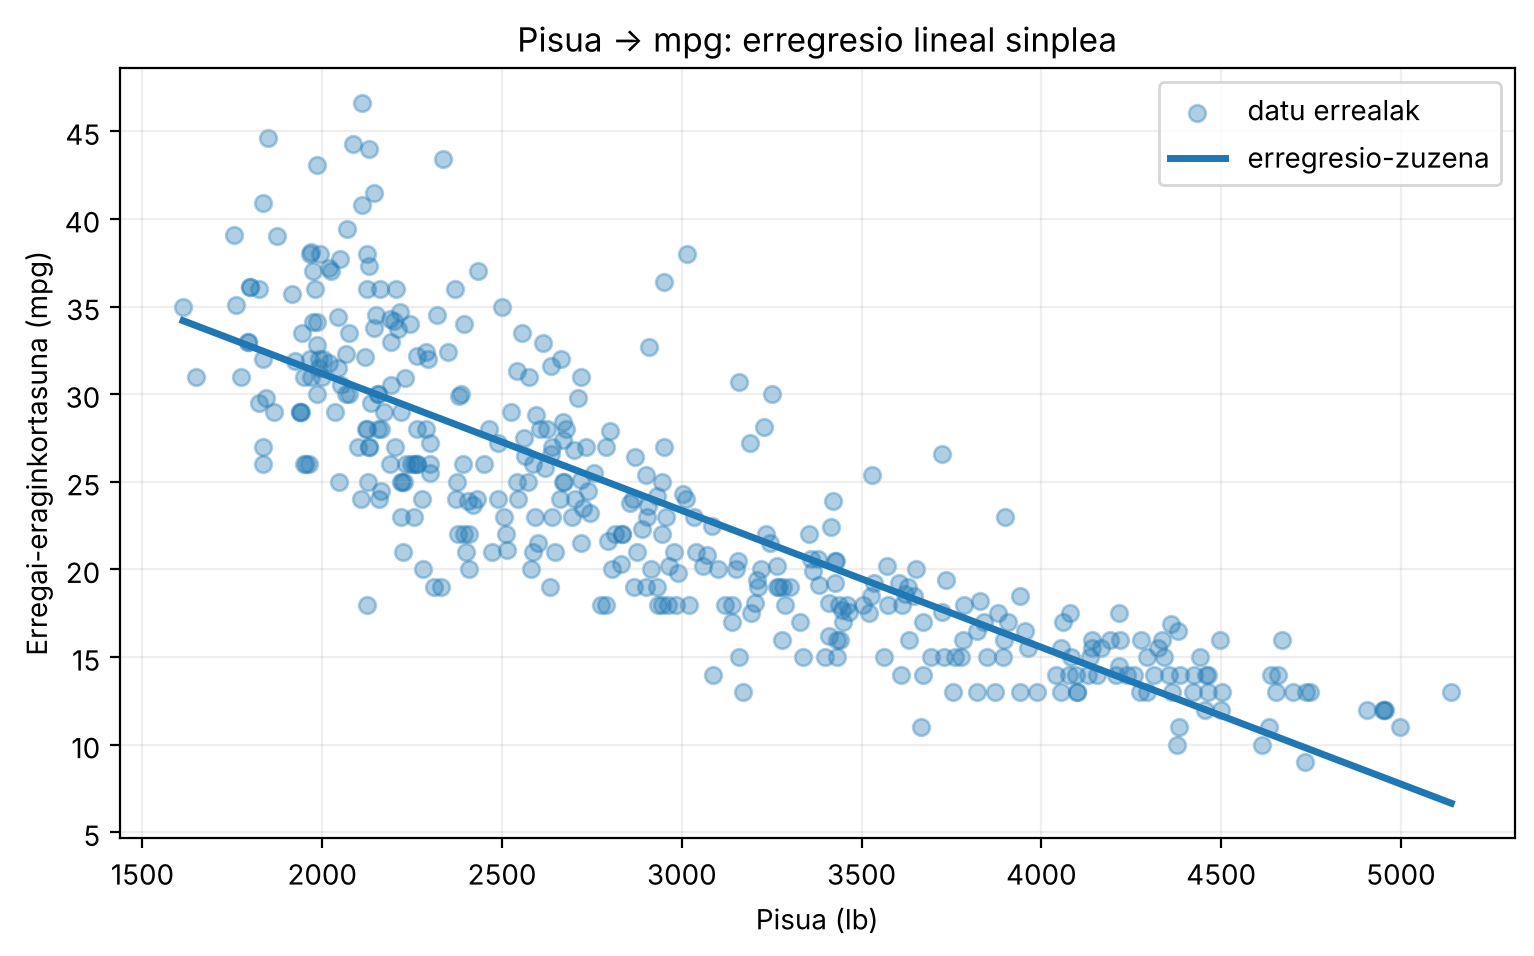

In [5]:
# Datu guztiak: scatter
plt.figure(
    figsize=(9, 5)
)

plt.scatter(
    df["weight"],
    df["mpg"],
    alpha=0.35,
    label="datu errealak"
)


# Lerro garbi bat marrazteko x-balio ordenatuak
x_line = np.linspace(
    df["weight"].min(),
    df["weight"].max(),
    200
)

X_line = pd.DataFrame({
    "weight": x_line
})

y_line = modeloa.predict(
    X_line
)


plt.plot(
    x_line,
    y_line,
    linewidth=2.5,
    label="erregresio-zuzena"
)

plt.xlabel(
    "Pisua (lb)"
)

plt.ylabel(
    "Erregai-eraginkortasuna (mpg)"
)

plt.title(
    "Pisua → mpg: erregresio lineal sinplea"
)

plt.legend()
plt.grid(
    alpha=0.2
)

plt.show()


# 1.7 — Auto berri baten iragarpena 🟡

3000 lb-ko auto baten mpg-a iragarriko dugu.

Gogoratu:

```text
datu berria
→ predict()
→ zenbaki jarraitua
```


In [6]:
auto_berria = pd.DataFrame({
    "weight": [
        3000
    ]
})


iragarpena = modeloa.predict(
    auto_berria
)


print(
    "3000 lb-ko autoa →",
    round(
        iragarpena[0],
        1
    ),
    "mpg"
)

3000 lb-ko autoa → 23.4 mpg


# 1.8 — 🔴 Neurona / ekuazioa eskuz

Orain `predict()` gabe.

Erabili:

$$
\hat{y} = wx + b
$$

3000 lb-ko autoarentzat kalkulatzeko.

Helburua:

> **`LinearRegression.predict()` eta `w*x+b` gauza bera egiten ari direla ikustea.**


In [7]:
# 🔴 KODETU ZEROTIK
#
# 1. pisua = 3000
# 2. eskuz = w * pisua + b
# 3. print()
# 4. konparatu modeloa.predict(auto_berria)-rekin


# IDATZI HEMEN:
# 1. pisua = 3000
pisua = 3000

# 2. eskuz = w * pisua + b
eskuz = w * pisua + b

# 3. print()
print("Eskuz kalkulatutako iragarpena:", round(eskuz, 1), "mpg")

# 4. konparatu modeloa.predict(auto_berria)-rekin
modeloaren_iragarpena = modeloa.predict(auto_berria)[0]
print("Modeloaren iragarpena (predict):", round(modeloaren_iragarpena, 1), "mpg")

print("\nEmaitza bera al da?:", np.isclose(eskuz, modeloaren_iragarpena))

Eskuz kalkulatutako iragarpena: 23.4 mpg
Modeloaren iragarpena (predict): 23.4 mpg

Emaitza bera al da?: True


# 1.9 — 🟢 Azken mental model-a

Osatu:

```text
INPUT
weight = x
    ↓

LINEAR REGRESSION
z = w · x + b
    ↓

OUTPUT
ŷ = zenbaki jarraitua
```

Eta Logistic Regression-ekin alderatuta:

```text
Linear Regression:
z = w·x+b
→ output zuzenean z

Logistic Regression:
z = w·x+b
→ sigmoid(z) = 1 / (1 + e^(-z))
→ probabilitatea
```

### Galdera nagusia

Zein da gaurko konexioa Deep Learning-ekin?

**ERANTZUNA:**
Erregresio lineala neurona artifizial bakar bat da aktibazio ez-linealik gabe (identity): sarrerak pisuekin biderkatu, bias-a gehitu eta emaitza zuzenean itzultzen du (`z = w·x + b`). Sare neuronal bat horrelako neurona asko geruzatan antolatzea da, eta neurona bakoitzaren irteerari aktibazio ez-lineal bat (ReLU, sigmoid...) aplikatzea. Beraz, gaur ikasi duguna (`w`, `b`, weighted sum + bias) Deep Learning-eko oinarrizko unitatea da.


# Ondorioak ✅

Gaur:

1. **Erregresioa** → zenbaki jarraitua iragartzea.
2. **Erregresio lineal sinplea** → feature bakarra + zuzen bat.
3. Ereduak `w` eta `b` ikasten ditu.
4. **Malda** jatorrizko unitateetan interpreta daiteke.
5. **Intercept-ak** ez du beti interpretazio fisiko erabilgarria.
6. `predict()` funtsean `w*x+b` aplikatzea da.
7. Erregresio lineala **weighted sum + bias** gisa ikus daiteke: Deep Learning-erako lehen zubia.

Hurrengo pausoetan:

```text
feature gehiago
→ multiple linear regression

errorea neurtu
→ MSE / MAE / RMSE / R²

eredua eskuz ikasi
→ gradient descent

neurona asko
→ Deep Learning
```
